In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor



In [4]:
from google.colab import files

uploaded = files.upload()

Saving house_prices.csv to house_prices.csv


In [5]:
df = pd.read_csv("house_prices.csv")

print(df.head())


   Area  Bedrooms  Age  Distance   Price
0  1200         2   10         5  250000
1  1500         3    8         4  320000
2  1800         3    5         3  400000
3  1000         2   15         8  210000
4  2200         4    3         2  520000


In [6]:
print("Shape of dataset:")
print(df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
print(df.describe())

Shape of dataset:
(20, 5)

Column names:
Index(['Area', 'Bedrooms', 'Age', 'Distance', 'Price'], dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Area      20 non-null     int64
 1   Bedrooms  20 non-null     int64
 2   Age       20 non-null     int64
 3   Distance  20 non-null     int64
 4   Price     20 non-null     int64
dtypes: int64(5)
memory usage: 932.0 bytes
None

Missing values:
Area        0
Bedrooms    0
Age         0
Distance    0
Price       0
dtype: int64

Statistical summary:
              Area   Bedrooms        Age   Distance          Price
count    20.000000  20.000000  20.000000  20.000000      20.000000
mean   1642.500000   3.000000   8.450000   4.800000  366000.000000
std     501.648598   0.858395   5.443248   2.726092  136204.181094
min     900.000000   2.000000   2.000000   1.000000  180000.000000

In [15]:

median_price = df["Price"].median()

df["Price_Category"] = np.where(
    df["Price"] < median_price,
    "Low",
    "High"
)

print("Median Price:", median_price)

print("\nPrice Categories:")
print(df["Price_Category"].value_counts())

Median Price: 355000.0

Price Categories:
Price_Category
Low     10
High    10
Name: count, dtype: int64


In [16]:
X = df[["Area", "Bedrooms", "Age", "Distance"]]

y = df["Price_Category"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Area  Bedrooms  Age  Distance
0  1200         2   10         5
1  1500         3    8         4
2  1800         3    5         3
3  1000         2   15         8
4  2200         4    3         2

Target:
0     Low
1     Low
2    High
3     Low
4    High
Name: Price_Category, dtype: object


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16, 4)
Testing data: (4, 4)


In [19]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=4
)

dt_model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [20]:
y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Predictions:")
print(y_pred_dt)

Decision Tree Predictions:
['High' 'High' 'Low' 'Low']


In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Decision Tree Classification")

print("Accuracy:",
      accuracy_score(y_test, y_pred_dt))

print("Precision:",
      precision_score(y_test, y_pred_dt, average="weighted"))

print("Recall:",
      recall_score(y_test, y_pred_dt, average="weighted"))

print("F1 Score:",
      f1_score(y_test, y_pred_dt, average="weighted"))

Decision Tree Classification
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [24]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Predictions:")
print(y_pred_rf)

Random Forest Predictions:
['High' 'High' 'Low' 'High']


In [25]:
print("Random Forest Classification")

print("Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("Precision:",
      precision_score(y_test, y_pred_rf, average="weighted"))

print("Recall:",
      recall_score(y_test, y_pred_rf, average="weighted"))

print("F1 Score:",
      f1_score(y_test, y_pred_rf, average="weighted"))

Random Forest Classification
Accuracy: 0.75
Precision: 0.8333333333333333
Recall: 0.75
F1 Score: 0.7333333333333334


In [26]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [28]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    C=1.0
)

svm_model.fit(X_train_scaled, y_train)

SVC()

In [29]:
y_pred_svm = svm_model.predict(X_test_scaled)

print("SVM Predictions:")
print(y_pred_svm)

SVM Predictions:
['High' 'High' 'Low' 'High']


In [30]:
print("Support Vector Machine Classification")

print("Accuracy:",
      accuracy_score(y_test, y_pred_svm))

print("Precision:",
      precision_score(y_test, y_pred_svm, average="weighted"))

print("Recall:",
      recall_score(y_test, y_pred_svm, average="weighted"))

print("F1 Score:",
      f1_score(y_test, y_pred_svm, average="weighted"))

Support Vector Machine Classification
Accuracy: 0.75
Precision: 0.8333333333333333
Recall: 0.75
F1 Score: 0.7333333333333334


In [32]:
from sklearn.metrics import classification_report

print("Decision Tree Classification Report")
print(classification_report(y_test, y_pred_dt))

Decision Tree Classification Report
              precision    recall  f1-score   support

        High       1.00      1.00      1.00         2
         Low       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



In [33]:
print("Random Forest Classification Report")
print(classification_report(y_test, y_pred_rf))

Random Forest Classification Report
              precision    recall  f1-score   support

        High       0.67      1.00      0.80         2
         Low       1.00      0.50      0.67         2

    accuracy                           0.75         4
   macro avg       0.83      0.75      0.73         4
weighted avg       0.83      0.75      0.73         4



In [34]:
print("SVM Classification Report")
print(classification_report(y_test, y_pred_svm))

SVM Classification Report
              precision    recall  f1-score   support

        High       0.67      1.00      0.80         2
         Low       1.00      0.50      0.67         2

    accuracy                           0.75         4
   macro avg       0.83      0.75      0.73         4
weighted avg       0.83      0.75      0.73         4



In [35]:
results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "SVM"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_svm)
    ],

    "Precision": [
        precision_score(y_test, y_pred_dt, average="weighted"),
        precision_score(y_test, y_pred_rf, average="weighted"),
        precision_score(y_test, y_pred_svm, average="weighted")
    ],

    "Recall": [
        recall_score(y_test, y_pred_dt, average="weighted"),
        recall_score(y_test, y_pred_rf, average="weighted"),
        recall_score(y_test, y_pred_svm, average="weighted")
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_dt, average="weighted"),
        f1_score(y_test, y_pred_rf, average="weighted"),
        f1_score(y_test, y_pred_svm, average="weighted")
    ]
})

print(results)

           Model  Accuracy  Precision  Recall  F1 Score
0  Decision Tree      1.00   1.000000    1.00  1.000000
1  Random Forest      0.75   0.833333    0.75  0.733333
2            SVM      0.75   0.833333    0.75  0.733333


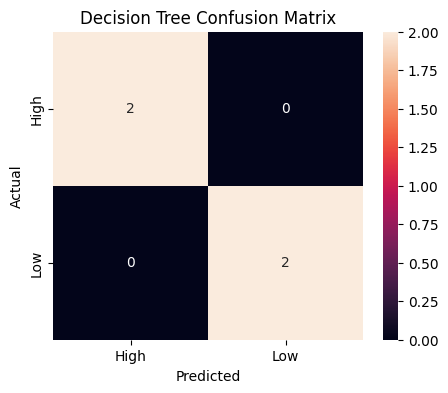

In [37]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    xticklabels=dt_model.classes_,
    yticklabels=dt_model.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")

plt.show()

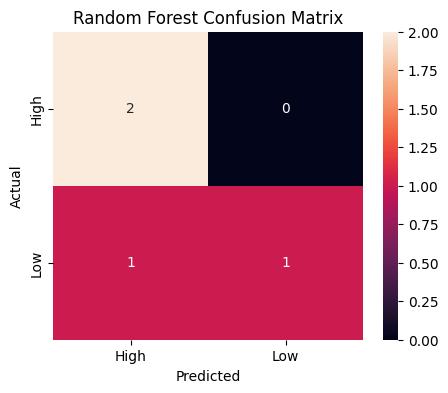

In [38]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    xticklabels=["High", "Low"],
    yticklabels=["High", "Low"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

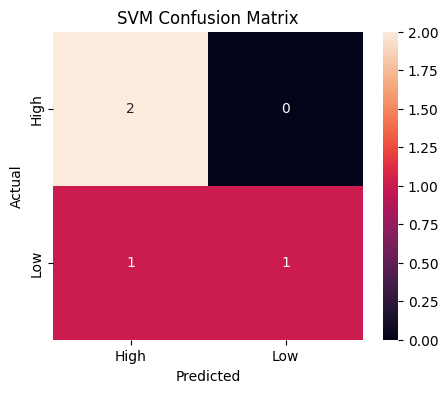

In [39]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    xticklabels=["High", "Low"],
    yticklabels=["High", "Low"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")

plt.show()

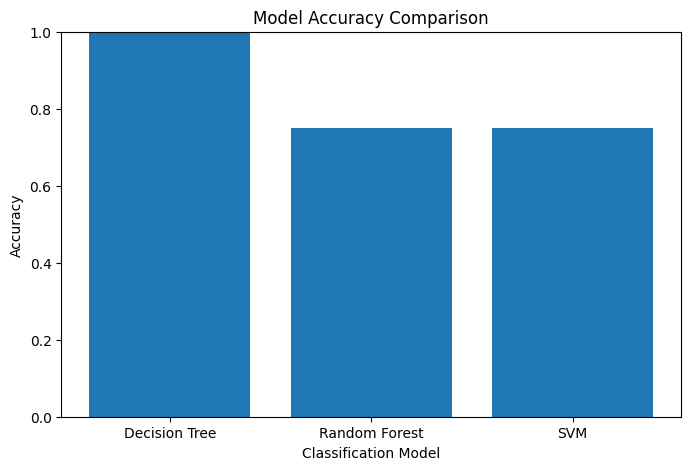

In [40]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Model"],
    results["Accuracy"]
)

plt.xlabel("Classification Model")
plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")

plt.ylim(0, 1)

plt.show()

from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

In [42]:
base_models = [
    ("decision_tree", DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    )),

    ("random_forest", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )),

    ("svm", SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ))
]

In [44]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

stacking_model = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(),
    cv=5
)

In [45]:
stacking_model.fit(
    X_train_scaled,
    y_train
)

StackingClassifier(cv=5,
                   estimators=[('decision_tree',
                                DecisionTreeClassifier(max_depth=4,
                                                       random_state=42)),
                               ('random_forest',
                                RandomForestClassifier(random_state=42)),
                               ('svm', SVC(probability=True, random_state=42))],
                   final_estimator=LogisticRegression())

In [46]:
y_pred_stack = stacking_model.predict(X_test_scaled)

print("Stacking Predictions:")
print(y_pred_stack)

Stacking Predictions:
['High' 'High' 'Low' 'Low']


In [47]:
stack_accuracy = accuracy_score(
    y_test,
    y_pred_stack
)

stack_precision = precision_score(
    y_test,
    y_pred_stack,
    average="weighted"
)

stack_recall = recall_score(
    y_test,
    y_pred_stack,
    average="weighted"
)

stack_f1 = f1_score(
    y_test,
    y_pred_stack,
    average="weighted"
)

print("Stacking Classifier")
print("-------------------------")
print("Accuracy :", stack_accuracy)
print("Precision:", stack_precision)
print("Recall   :", stack_recall)
print("F1 Score :", stack_f1)

Stacking Classifier
-------------------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0


In [48]:
print("Stacking Classification Report")
print(classification_report(y_test, y_pred_stack))

Stacking Classification Report
              precision    recall  f1-score   support

        High       1.00      1.00      1.00         2
         Low       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



In [49]:
results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "SVM",
        "Stacking"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_stack)
    ],

    "Precision": [
        precision_score(y_test, y_pred_dt, average="weighted"),
        precision_score(y_test, y_pred_rf, average="weighted"),
        precision_score(y_test, y_pred_svm, average="weighted"),
        precision_score(y_test, y_pred_stack, average="weighted")
    ],

    "Recall": [
        recall_score(y_test, y_pred_dt, average="weighted"),
        recall_score(y_test, y_pred_rf, average="weighted"),
        recall_score(y_test, y_pred_svm, average="weighted"),
        recall_score(y_test, y_pred_stack, average="weighted")
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_dt, average="weighted"),
        f1_score(y_test, y_pred_rf, average="weighted"),
        f1_score(y_test, y_pred_svm, average="weighted"),
        f1_score(y_test, y_pred_stack, average="weighted")
    ]
})

print(results)

           Model  Accuracy  Precision  Recall  F1 Score
0  Decision Tree      1.00   1.000000    1.00  1.000000
1  Random Forest      0.75   0.833333    0.75  0.733333
2            SVM      0.75   0.833333    0.75  0.733333
3       Stacking      1.00   1.000000    1.00  1.000000


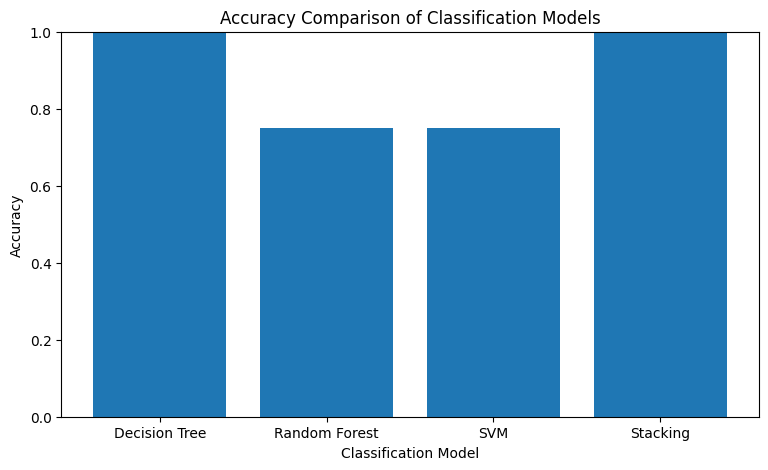

In [50]:
plt.figure(figsize=(9, 5))

plt.bar(
    results["Model"],
    results["Accuracy"]
)

plt.xlabel("Classification Model")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison of Classification Models")

plt.ylim(0, 1)

plt.show()

In [51]:
y_test_binary = (y_test == "High").astype(int)

In [52]:
dt_prob = dt_model.predict_proba(X_test)[:, 1]

In [53]:
rf_prob = rf_model.predict_proba(X_test)[:, 1]

In [54]:
SVC(kernel="rbf", C=1.0)

SVC()

In [55]:
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    probability=True,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

In [56]:
svm_prob = svm_model.predict_proba(X_test_scaled)[:, 1]

In [57]:
stack_prob = stacking_model.predict_proba(X_test_scaled)[:, 1]

In [58]:
from sklearn.metrics import roc_curve, roc_auc_score

In [59]:
fpr_dt, tpr_dt, _ = roc_curve(y_test_binary, dt_prob)
auc_dt = roc_auc_score(y_test_binary, dt_prob)

fpr_rf, tpr_rf, _ = roc_curve(y_test_binary, rf_prob)
auc_rf = roc_auc_score(y_test_binary, rf_prob)

fpr_svm, tpr_svm, _ = roc_curve(y_test_binary, svm_prob)
auc_svm = roc_auc_score(y_test_binary, svm_prob)

fpr_stack, tpr_stack, _ = roc_curve(y_test_binary, stack_prob)
auc_stack = roc_auc_score(y_test_binary, stack_prob)

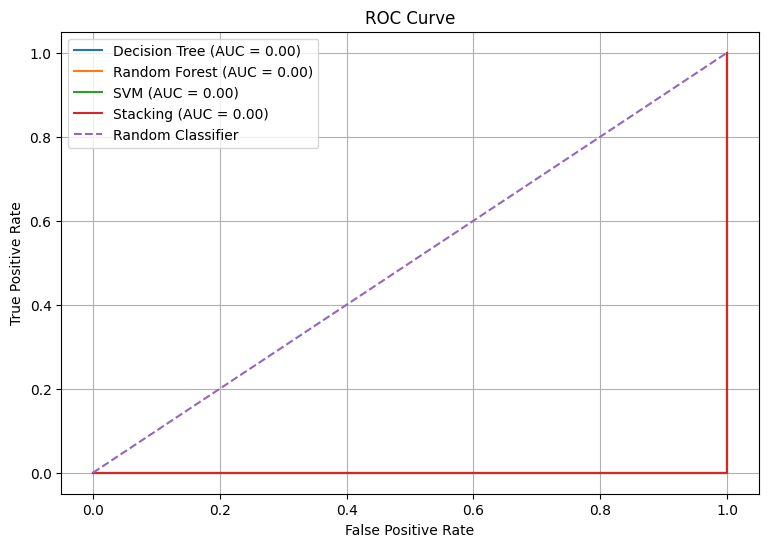

In [60]:
plt.figure(figsize=(9, 6))

plt.plot(
    fpr_dt,
    tpr_dt,
    label=f"Decision Tree (AUC = {auc_dt:.2f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.2f})"
)

plt.plot(
    fpr_svm,
    tpr_svm,
    label=f"SVM (AUC = {auc_svm:.2f})"
)

plt.plot(
    fpr_stack,
    tpr_stack,
    label=f"Stacking (AUC = {auc_stack:.2f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.grid()

plt.show()

In [61]:
auc_results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "SVM",
        "Stacking"
    ],

    "AUC": [
        auc_dt,
        auc_rf,
        auc_svm,
        auc_stack
    ]
})

print(auc_results)

           Model  AUC
0  Decision Tree  0.0
1  Random Forest  0.0
2            SVM  0.0
3       Stacking  0.0
